In [1]:
from tld import get_fld
from urllib.parse import urlparse
import json
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
hars = {}
for crawl in ["desktop", "mobile", "block", "ignore"]:
    # Each crawl stores its HAR files in its own folder
    ordner = Path("../crawl_data_" + crawl)
    hars[crawl] = {}
    for har_path in ordner.glob("*.har"):
        # File name without ".har" is the site's domain
        domain = har_path.stem
        # Parse the HAR file (JSON) into a Python dictionary
        with open(har_path, encoding="utf-8") as har_file:
            har = json.load(har_file)
        hars[crawl][domain] = har

Get all the entries that were not blocked

In [3]:
# Returns only the HAR entries that actually received a response (copied from Assignment 1 and only adjusted the error condition)
def get_valid_entries(har):
    valid = []
    for entry in har['log']['entries']:
        if entry['response']['status'] <= 0:
            continue
        if entry['response'].get('_failureText'):
            continue
        valid.append(entry)
    return valid

Get the number of valid entries

In [4]:
def get_number_of_valid_entries(valid_entries):
    return len(valid_entries)

Get the number of third party requests per website

In [5]:
# copied from Assignment 1 (only added the silent fail)
def is_third_party(page_url, request_url):
    request_domain = get_fld(request_url, fail_silently=True)
    if request_domain is None:
        return False
    return get_fld(page_url) != request_domain

# copied from Assignment 1 (but count them now)
def getNumThirdPartyRequests(entries, page_url):
    count = 0
    for entry in entries:
        req_url = entry['request']['url']
        if is_third_party(page_url, req_url):
            count += 1
    return count

Get the number of third-party domains per website

In [6]:
# copied from Assignment 1
def get_third_party_domains(entries, page_url):
    tp_domains = set()
    for entry in entries:
        req_url = entry['request']['url']
        if is_third_party(page_url, req_url):
            tp_domains.add(get_fld(req_url))
    return tp_domains

def number_of_distinct_third_party_domains(domains):
    return len(domains)

Number of distinct third-party entities per website

In [7]:
# Load Disconnect's entity list: each entity (company) owns a set of domains
entities = json.loads(open("../crawler_src/disconnect/entities.json").read())
# Build a lookup table
domain_to_entity = {}
for entity_name, entity_info in entities["entities"].items():
    # properties are the entities own websites, resources the domains it uses for tracking content
    for domain in entity_info["properties"] + entity_info["resources"]:
        domain_to_entity[domain] = entity_name


def get_third_party_entities(domains, map):
    # Map each third-party domain to its owning entity, domains that are not in Disconnect's list are skipped
    thirdPartyEntities = set()
    for domain in domains:
        if (domain in map):
            thirdPartyEntities.add(map[domain])
    return thirdPartyEntities

def get_number_of_distict_third_party_entities_per_website(third_party_entities):
    return len(third_party_entities)

Find out if websites sends at least one request to an advertisement domain

In [8]:
# Load Disconnect's blocklist 
services_file = open("../crawler_src/disconnect/services.json", encoding="utf-8")
services = json.load(services_file)
services_file.close()

#same idea as domain_to_entity above, but a domain can belong to several categories so we use a set)
domain_to_categories = {}
for category, entity_list in services["categories"].items():
    for entity_dict in entity_list:
        for entity_name, entity_info in entity_dict.items():
            for key,value in entity_info.items():
                # Only lists contain domains
                if isinstance(value, list):
                    for domain in value:
                        domain_to_categories.setdefault(domain, set()).add(category)

def has_website_send_request(valid_entries, category):
    # True as soon as one request goes to a domain of the given category, otherwise False
    for entry in valid_entries:
        request_url = entry["request"]["url"]
        # Reduce the URL to its eTLD+1
        request_domain = get_fld(request_url, fail_silently=True)
        # Skip URLs without a valid domain
        if request_domain is None:
            continue
        if category in domain_to_categories.get(request_domain,set()) :
            return True
    return False


Get the country of the Website

In [9]:
# sites.csv lists every crawled website with its country and university name
sites = pd.read_csv("../sites.csv")
# same procedure as above but only one county so not set needed
domain_to_country = {}
for domain, country in zip(sites["domain"], sites["country"]):
    domain_to_country[domain] = country


Prepare data for plotting 

In [10]:
# Final page URL after redirects: first main document response that is not a redirect (3xx)
def get_page_url(har):
    for entry in har['log']['entries']:
        status = entry['response']['status']
        if entry.get('_resourceType') == 'document' and status > 0 and not (300 <= status < 400):
            return entry['request']['url']
    return None

# One dictionary per (crawl, site) combination
rows = []
for crawl in hars:
    for site in hars[crawl]:
        har = hars[crawl][site]
        page_url = get_page_url(har)
        valid_entries = get_valid_entries(har)
        third_party_domains = get_third_party_domains(valid_entries, page_url)
        third_party_entities = get_third_party_entities(third_party_domains, domain_to_entity)

        # append all the rows of the different metrics we calculated and need for the plots
        rows.append({
            "site": site,
            "mode": crawl,
            "num_requests": get_number_of_valid_entries(valid_entries),
            "num_third_party_requests": getNumThirdPartyRequests(valid_entries, page_url),
            "num_dist_third_party_domains": number_of_distinct_third_party_domains(third_party_domains),
            "num_dist_third_party_entites_per_website": get_number_of_distict_third_party_entities_per_website(third_party_entities),
            "contacts_advertising": has_website_send_request(valid_entries, "Advertising"),
            "contacts_analytics":   has_website_send_request(valid_entries, "Analytics"),
            "country": domain_to_country[site]
        })

df = pd.DataFrame(rows)
df

,site,mode,num_requests,num_third_party_requests,num_dist_third_party_domains,num_dist_third_party_entites_per_website,contacts_advertising,contacts_analytics,country
0,eur.nl,desktop,63,13,7,4,True,False,nl
1,birmingham.ac.uk,desktop,110,62,22,6,True,False,uk
2,vu.nl,desktop,95,70,14,5,True,True,nl
3,st-andrews.ac.uk,desktop,85,50,15,3,True,True,uk
4,maastrichtuniversity.nl,desktop,61,35,6,3,True,True,nl
...,...,...,...,...,...,...,...,...,...
115,warwick.ac.uk,ignore,78,34,4,0,False,False,uk
116,northwestern.edu,ignore,79,24,7,1,False,True,us
117,ru.nl,ignore,34,5,3,2,False,True,nl
118,caltech.edu,ignore,74,19,6,2,False,True,us


Plots for 1a - 1d

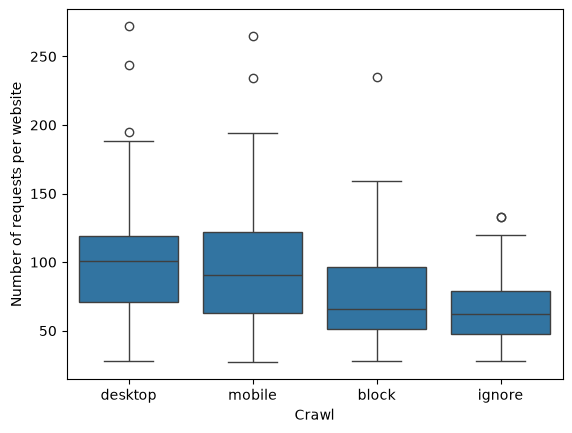

In [11]:
sns.boxplot(df, x="mode", y="num_requests")
plt.xlabel("Crawl")
plt.ylabel("Number of requests per website")
plt.show()

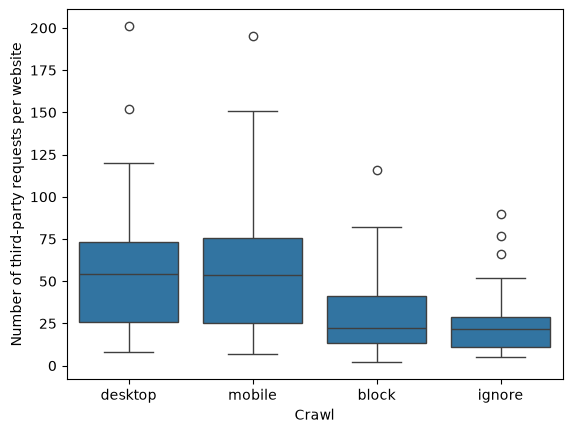

In [12]:
sns.boxplot(df, x="mode", y="num_third_party_requests")
plt.xlabel("Crawl")
plt.ylabel("Number of third-party requests per website")
plt.show()

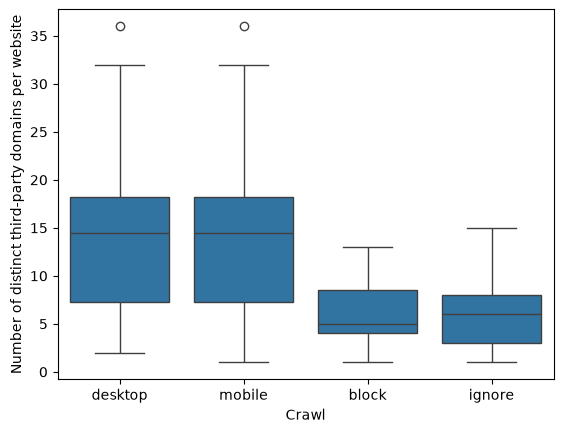

In [13]:
sns.boxplot(df, x="mode", y="num_dist_third_party_domains")
plt.xlabel("Crawl")
plt.ylabel("Number of distinct third-party domains per website")
plt.show()

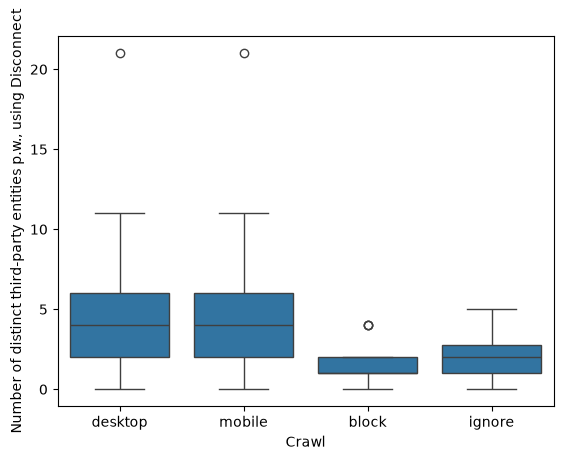

In [14]:
sns.boxplot(df, x="mode", y="num_dist_third_party_entites_per_website")
plt.xlabel("Crawl")
plt.ylabel("Number of distinct third-party entities p.w., using Disconnect")
plt.show()

Create Table to compare data from 1a - 1d

In [15]:
metrics = ["num_requests", "num_third_party_requests", "num_dist_third_party_domains", "num_dist_third_party_entites_per_website"]
table = df.groupby("mode")[metrics].agg(["min", "median", "max"]).T.unstack()
table

mode                                     block               desktop         \
                                           min median    max     min median   
num_requests                              28.0   66.0  235.0    28.0  101.0   
num_third_party_requests                   2.0   22.0  116.0     8.0   54.5   
num_dist_third_party_domains               1.0    5.0   13.0     2.0   14.5   
num_dist_third_party_entites_per_website   0.0    1.0    4.0     0.0    4.0   

mode                                            ignore               mobile  \
                                            max    min median    max    min   
num_requests                              272.0   28.0   62.0  133.0   27.0   
num_third_party_requests                  201.0    5.0   21.5   90.0    7.0   
num_dist_third_party_domains               36.0    1.0    6.0   15.0    1.0   
num_dist_third_party_entites_per_website   21.0    0.0    2.0    5.0    0.0   

mode                                                    
                                         median    max  
num_requests                               90.5  265.0  
num_third_party_requests                   53.5  195.0  
num_dist_third_party_domains               14.5   36.0  
num_dist_third_party_entites_per_website    4.0   21.0

Barplot for 3 a,b

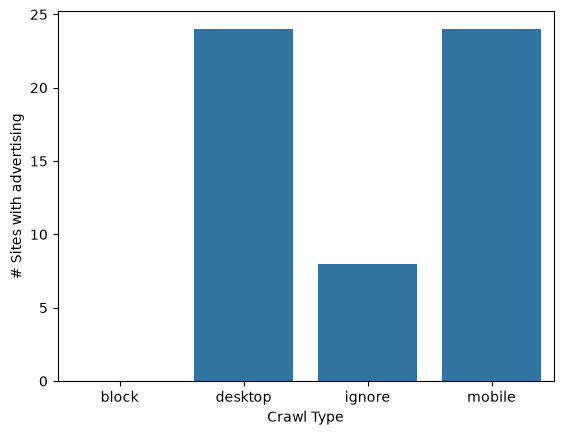

In [16]:
advertising_counts = df.groupby("mode")["contacts_advertising"].sum().reset_index()
sns.barplot(advertising_counts, x="mode", y="contacts_advertising")
plt.xlabel("Crawl Type")
plt.ylabel("# Sites with advertising")
plt.show()

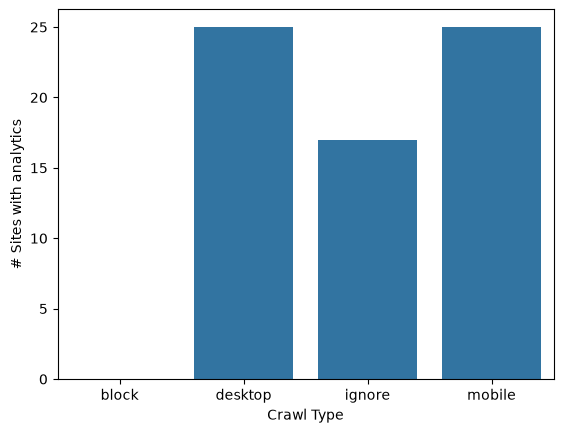

In [17]:
analytics_counts = df.groupby("mode")["contacts_analytics"].sum().reset_index()
sns.barplot(analytics_counts, x="mode", y="contacts_analytics")
plt.xlabel("Crawl Type")
plt.ylabel("# Sites with analytics")
plt.show()

Analysis for 4

In [18]:
country_table = df[df["mode"]=="desktop"].groupby("country")[metrics].agg(["min", "median", "max"]).T.unstack()
country_table

country                                     nl                  uk         \
                                           min median    max   min median   
num_requests                              28.0   69.0  272.0  85.0  143.5   
num_third_party_requests                   9.0   37.5   74.0  50.0  105.0   
num_dist_third_party_domains               3.0   10.5   19.0  15.0   22.0   
num_dist_third_party_entites_per_website   1.0    4.5    8.0   2.0    7.5   

country                                            us                
                                            max   min median    max  
num_requests                              244.0  28.0   82.5  120.0  
num_third_party_requests                  201.0   8.0   27.0   77.0  
num_dist_third_party_domains               36.0   2.0    8.5   15.0  
num_dist_third_party_entites_per_website   21.0   0.0    2.0    5.0

Analysis for 5

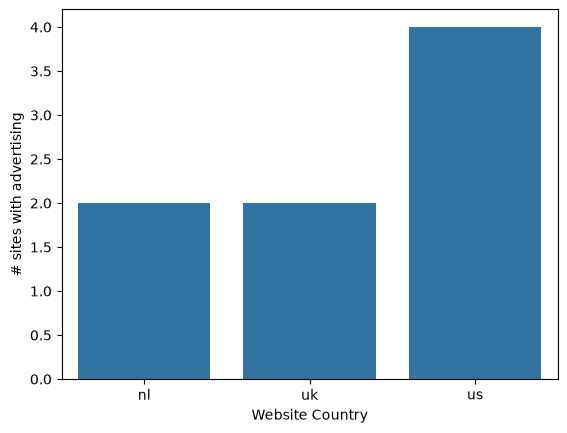

In [19]:
ignore_adveritising_counts = df[df["mode"]=="ignore"].groupby("country")["contacts_advertising"].sum().reset_index()

sns.barplot(ignore_adveritising_counts, x="country", y="contacts_advertising")
plt.xlabel("Website Country")
plt.ylabel("# sites with advertising")
plt.show()



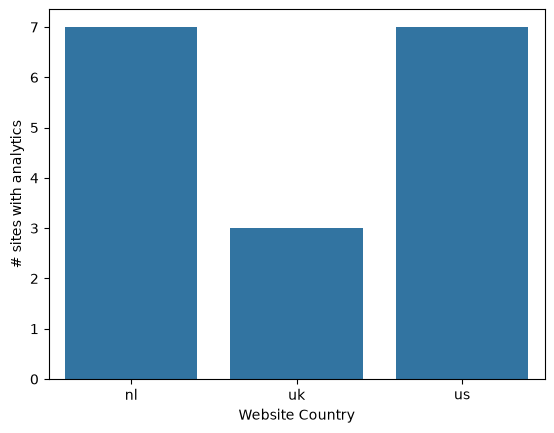

In [20]:
ignore_analytics_counts = df[df["mode"]=="ignore"].groupby("country")["contacts_analytics"].sum().reset_index()

sns.barplot(ignore_analytics_counts, x="country", y="contacts_analytics")
plt.xlabel("Website Country")
plt.ylabel("# sites with analytics")
plt.show()


Analysis for 10

In [21]:
def get_response_header_values(entry, header_name):
    return [header["value"] for header in entry["response"]["headers"] if header["name"].lower() == header_name]

def get_first_party_entries(har):
    page_url = get_page_url(har)
    first_party_entries = []
    for entry in get_valid_entries(har):
        request_domain = get_fld(entry["request"]["url"], fail_silently=True)
        if request_domain is not None and not is_third_party(page_url, entry["request"]["url"]):
            first_party_entries.append(entry)
    return first_party_entries

def get_disabled_permissions(permissions_policy):
    # directives are comma separated: "camera=(), geolocation=(self)"
    disabled_permissions = set()
    for directive in permissions_policy.split(","):
        if "=" not in directive:
            continue
        permission_name, allowlist = directive.split("=", 1)
        if allowlist.strip() == "()":
            disabled_permissions.add(permission_name.strip().lower())
    return disabled_permissions

In [22]:
permission_to_sites = {}
for site, har in hars["mobile"].items():
    for entry in get_first_party_entries(har):
        for permissions_policy in get_response_header_values(entry, "permissions-policy"):
            for permission_name in get_disabled_permissions(permissions_policy):
                permission_to_sites.setdefault(permission_name, set()).add(site)

disabled_permissions_table = pd.DataFrame(
    [(permission_name, len(sites_with_permission)) for permission_name, sites_with_permission in permission_to_sites.items()],
    columns=["Permission name", "Number of distinct websites where this permission was disabled"],
).sort_values(["Number of distinct websites where this permission was disabled", "Permission name"], ascending=[False, True]).reset_index(drop=True)

print("Table Q10: The five permissions most often explicitly disabled (empty allowlist) in first-party Permissions-Policy headers, Mobile crawl")
disabled_permissions_table.head(5)

Table Q10: The five permissions most often explicitly disabled (empty allowlist) in first-party Permissions-Policy headers, Mobile crawl


,Permission name,Number of distinct websites where this permission was disabled
0,microphone,5
1,camera,4
2,gyroscope,3
3,magnetometer,3
4,payment,2


Analysis for 11

In [23]:
def sets_no_referrer(referrer_policy):
    # the header can hold a comma separated list, so compare each token exactly
    tokens = [token.strip().lower() for token in referrer_policy.split(",")]
    return "no-referrer" in tokens

no_referrer_rows = []
for site, har in hars["desktop"].items():
    for entry in get_first_party_entries(har):
        if any(sets_no_referrer(value) for value in get_response_header_values(entry, "referrer-policy")):
            no_referrer_rows.append({"Website": site, "Country": domain_to_country[site].upper()})
            break

no_referrer_table = pd.DataFrame(no_referrer_rows).sort_values(["Country", "Website"]).reset_index(drop=True)
print("Table Q11: Websites where at least one first-party response set a no-referrer Referrer-Policy header, Desktop crawl")
no_referrer_table

Table Q11: Websites where at least one first-party response set a no-referrer Referrer-Policy header, Desktop crawl


,Website,Country
0,eur.nl,NL
1,utwente.nl,NL
2,uva.nl,NL


Analysis for 12

In [24]:
import dns.resolver
from urllib.parse import urlparse

def get_cname_chain(hostname):
    # follow CNAME records until the name no longer has one (e.g. a.example.com -> b.cdn.net -> c.tracker.com)
    cname_chain = []
    current_name = hostname
    while True:
        try:
            answer = dns.resolver.resolve(current_name, "CNAME")
        except Exception:
            break
        current_name = str(answer[0].target).rstrip(".")
        cname_chain.append(current_name)
    return cname_chain

def get_listed_domain(hostname):
    labels = hostname.lower().split(".")
    for start in range(len(labels) - 1):
        candidate = ".".join(labels[start:])
        if candidate in domain_to_categories:
            return candidate
    return None

In [25]:
def get_first_party_hostnames(har):
    return {urlparse(entry["request"]["url"]).hostname for entry in get_first_party_entries(har)}

def get_cname_tracking_rows(crawl):
    rows_for_crawl = []
    for site, har in hars[crawl].items():
        for hostname in get_first_party_hostnames(har):
            for cname in get_cname_chain(hostname):
                cname_domain = get_listed_domain(cname)
                if cname_domain is None:
                    continue
                rows_for_crawl.append({
                    "Website": site,
                    "First-party subdomain": hostname,
                    "CNAME record": cname,
                    "CNAME entity": domain_to_entity[cname_domain],
                    "Disconnect categories": ", ".join(sorted(domain_to_categories[cname_domain])),
                })
                break
    columns = ["Website", "First-party subdomain", "CNAME record", "CNAME entity", "Disconnect categories"]
    return pd.DataFrame(rows_for_crawl, columns=columns).sort_values(["Website", "First-party subdomain"]).reset_index(drop=True)

In [26]:
print("Table Q12 (Desktop): First-party subdomains with a CNAME record listed in Disconnect's blocklist, Crawl-Desktop")
get_cname_tracking_rows("desktop")

Table Q12 (Desktop): First-party subdomains with a CNAME record listed in Disconnect's blocklist, Crawl-Desktop


,Website,First-party subdomain,CNAME record,CNAME entity,Disconnect categories
0,manchester.ac.uk,www.manchester.ac.uk,duc7h5khrpi4j.cloudfront.net,Amazon,Content
1,nottingham.ac.uk,smetrics.nottingham.ac.uk,oacflwpnfh.data.adobedc.net,Adobe,Analytics
2,uchicago.edu,www.uchicago.edu,hubba882888a582-prod-frontdoor-endpoint-gkbrer...,Microsoft,Content
3,ucla.edu,cdn.webcomponents.ucla.edu,d3nstw201xsr54.cloudfront.net,Amazon,Content
4,ucla.edu,www.ucla.edu,d1zev4mn1zpfbc.cloudfront.net,Amazon,Content


In [27]:
print("Table Q12 (Mobile): First-party subdomains with a CNAME record listed in Disconnect's blocklist, Crawl-Mobile")
get_cname_tracking_rows("mobile")

Table Q12 (Mobile): First-party subdomains with a CNAME record listed in Disconnect's blocklist, Crawl-Mobile


,Website,First-party subdomain,CNAME record,CNAME entity,Disconnect categories
0,manchester.ac.uk,www.manchester.ac.uk,duc7h5khrpi4j.cloudfront.net,Amazon,Content
1,nottingham.ac.uk,smetrics.nottingham.ac.uk,oacflwpnfh.data.adobedc.net,Adobe,Analytics
2,uchicago.edu,www.uchicago.edu,hubba882888a582-prod-frontdoor-endpoint-gkbrer...,Microsoft,Content
3,ucla.edu,cdn.webcomponents.ucla.edu,d3nstw201xsr54.cloudfront.net,Amazon,Content
4,ucla.edu,www.ucla.edu,d1zev4mn1zpfbc.cloudfront.net,Amazon,Content


In [28]:
print("Table Q12 (Block): First-party subdomains with a CNAME record listed in Disconnect's blocklist, Crawl-Block")
get_cname_tracking_rows("block")

Table Q12 (Block): First-party subdomains with a CNAME record listed in Disconnect's blocklist, Crawl-Block


,Website,First-party subdomain,CNAME record,CNAME entity,Disconnect categories
0,manchester.ac.uk,www.manchester.ac.uk,duc7h5khrpi4j.cloudfront.net,Amazon,Content
1,nottingham.ac.uk,smetrics.nottingham.ac.uk,oacflwpnfh.data.adobedc.net,Adobe,Analytics
2,uchicago.edu,www.uchicago.edu,hubba882888a582-prod-frontdoor-endpoint-gkbrer...,Microsoft,Content
3,ucla.edu,cdn.webcomponents.ucla.edu,d3nstw201xsr54.cloudfront.net,Amazon,Content
4,ucla.edu,www.ucla.edu,d1zev4mn1zpfbc.cloudfront.net,Amazon,Content


In [29]:
print("Table Q12 (Ignore): First-party subdomains with a CNAME record listed in Disconnect's blocklist, Crawl-Ignore")
get_cname_tracking_rows("ignore")

Table Q12 (Ignore): First-party subdomains with a CNAME record listed in Disconnect's blocklist, Crawl-Ignore


,Website,First-party subdomain,CNAME record,CNAME entity,Disconnect categories
0,manchester.ac.uk,www.manchester.ac.uk,duc7h5khrpi4j.cloudfront.net,Amazon,Content
1,uchicago.edu,www.uchicago.edu,hubba882888a582-prod-frontdoor-endpoint-gkbrer...,Microsoft,Content
2,ucla.edu,cdn.webcomponents.ucla.edu,d3nstw201xsr54.cloudfront.net,Amazon,Content
3,ucla.edu,www.ucla.edu,d1zev4mn1zpfbc.cloudfront.net,Amazon,Content


Analysis for 13

a) Consent matters more than anything else in our data. Without interacting with the banner (Ignore), the average website contacted 6 distinct third-party domains, compared with 14.5 after "Accept all" (Desktop). Blocking Disconnect's tracker categories while still accepting (Block) brought this down to 5. The CNAME analysis (Q12) shows the limits of domain-based blocking: on nottingham.ac.uk the first-party subdomain `smetrics.nottingham.ac.uk` points via CNAME to Adobe's analytics endpoint (`*.data.adobedc.net`). It was still contacted in the Block crawl because its name looks first-party.

b) We did the DNS lookups for Q12 during the analysis (as recommended), not during the crawl, and from a single resolver. If a CNAME record changed between the crawl and the analysis, or depends on the resolver's location, Q12 could report trackers that did not exist at crawl time. We also crawled each site once, from one vantage point (NL), so geo-dependent consent banners are not captured.

c) group question